# 00 - Orientation and Setup

**Part A - Foundations - Petrophys Curriculum**

Welcome. This is the first notebook of the *petrophys* teaching curriculum. By the
end of it you will know what the library is for, how to reach the well-log data that
ships inside it, and where each later notebook fits into the bigger picture.

No prior experience with *petrophys* is assumed - only a working knowledge of basic
petrophysics (gamma ray, density, neutron, resistivity, porosity, water saturation).

## Learning goals

- Understand what *petrophys* is: a comprehensive, open well-log and
  formation-evaluation platform.
- Load the **bundled sample data** with `petrophys.sample(...)` and discover what is
  available with `petrophys.list_samples(...)`.
- Take a guided tour of the **two teaching datasets**:
  - *Geolink* - North Sea **clastic** wells (primary teaching well `30_6-5`).
  - *Costa* - a 17-well **carbonate** field (`HW-3 ... HW-32`).
- Read the **curriculum roadmap** (Parts A and B) so you know where you are going.
- Know honestly **what is not covered yet** so you set the right expectations.

## Why this matters

Formation evaluation is the discipline of turning raw borehole measurements into
answers a subsurface team can act on: *How much rock is reservoir? How porous is it?
How much of the pore space is hydrocarbon rather than water?*

The workflow always starts the same way - **get the data in, and understand it** -
before any physics is applied. This notebook is that starting point. Everything later
(clay volume, porosity, saturation, permeability, net pay, lithology solving) builds on
the `Well` and `Curve` objects you will meet here.

### Prerequisites

None. This is the entry point. The only requirement is that the `petrophys` package is
importable in the active kernel (it ships with all sample data, so no external files or
downloads are needed).

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las

print('petrophys version:', petrophys.__version__)
print('Ready. All sample data is bundled inside the package.')

petrophys version: 0.1.0
Ready. All sample data is bundled inside the package.


## 1. What is petrophys?

*petrophys* is a Python platform for **well-log analysis and formation evaluation**. It
covers the full path from a raw LAS/DLIS file to interpreted reservoir properties, and
groups its functionality into focused sub-packages. A high-level tour:

| Sub-package | Purpose |
|---|---|
| `petrophys.io` | Read/write well data (`read_las`, `read_dlis`, exporters) |
| `petrophys.base` | Core data model: the `Well` and `Curve` objects |
| `petrophys.qaqc` | Quality control: standardization, bad-hole, value-range, normalization |
| `petrophys.clay_volume` | Shale/clay volume from GR, SP, neutron-density |
| `petrophys.petrophysics` | Porosity, saturation, permeability, cementation |
| `petrophys.lithology` | Multi-mineral solving |
| `petrophys.reservoir` | Net pay, BVW, rock-quality index, flow units |
| `petrophys.summation` | Hydrocarbon pore volume, OOIP/OGIP, zone summaries |
| `petrophys.visualization` | Triple-combo, crossplots, Pickett, log viewers |

We will meet many of these across the curriculum. For now, the important idea is that
**every one of them consumes the same `Well` object** - so learning to load and inspect
a well (Part A) unlocks everything else.

In [2]:
# Discover the bundled sample catalogue.
all_samples = petrophys.list_samples()
geolink = petrophys.list_samples('geolink')
costa = petrophys.list_samples('costa')

print('Total bundled wells :', len(all_samples))
print('Geolink (clastic)   :', geolink)
print('Costa   (carbonate) : %d wells -> %s ...' % (len(costa), costa[:4]))

Total bundled wells : 24
Geolink (clastic)   : ['15_9-14', '16_7-1', '25_5-1', '30_6-5']
Costa   (carbonate) : 17 wells -> ['HW-10', 'HW-24', 'HW-25', 'HW-26'] ...


## 2. Accessing bundled data

Two functions are all you need to reach the sample data:

- `petrophys.list_samples(kind=None)` - returns the list of available well names. Pass
  `'geolink'` or `'costa'` to filter by dataset, or nothing to list everything.
- `petrophys.sample(name)` - returns the **absolute path** to that well's LAS file. Feed
  that path straight into `read_las(...)`.

Because the data lives inside the installed package, this works on any machine with no
setup - no downloads, no credentials, no path juggling.

In [3]:
# sample() returns a filesystem path to the LAS file.
path_30_6_5 = petrophys.sample('30_6-5')
path_hw3 = petrophys.sample('HW-3')

print('30_6-5 LAS path:', path_30_6_5)
print('HW-3   LAS path:', path_hw3)

30_6-5 LAS path: /path/to/petrophys/petrophys/data/geolink/30_6-5.las
HW-3   LAS path: /path/to/petrophys/petrophys/data/costa/HW-3.las


## 3. Tour - dataset one: Geolink (North Sea clastics)

The **Geolink** wells are siliciclastic (sand/shale) wells from the Norwegian North
Sea. Our **primary teaching well is `30_6-5`** from the Oseberg area: it is unusually
rich, carrying not just the standard triple-combo logs but also core-calibrated
porosity/permeability and a supplied lithology track - ideal for teaching.

Let us load it and read off the basic facts.

In [4]:
w_geo = read_las(petrophys.sample('30_6-5'))

# header.field can contain non-ASCII field names; print an ASCII-safe version.
field_ascii = (w_geo.header.field or '').encode('ascii', 'replace').decode('ascii')

print('=== Geolink well 30_6-5 ===')
print('Well name    :', w_geo.name)
print('Field        :', field_ascii)
print('UWI          :', w_geo.header.uwi)
print('# curves     :', w_geo.n_curves)
print('# samples    :', w_geo.n_samples)
print('Depth unit   :', w_geo.depth_unit)
print('Depth range  : %.2f -> %.2f %s' % (w_geo.start_depth, w_geo.stop_depth, w_geo.depth_unit))
print('Sample step  : %.4f %s' % (w_geo.step, w_geo.depth_unit))
print()
print('Curves:')
print('  ' + ', '.join(w_geo.curves))

=== Geolink well 30_6-5 ===
Well name    : 30/6-5
Field        : OSEBERG ??ST
UWI          : 30/6-5
# curves     : 20
# samples    : 22176
Depth unit   : m
Depth range  : 176.61 -> 3556.08 m
Sample step  : 0.1524 m

Curves:
  LITHOLOGY_GEOLINK, CALI, DRHO, NPHI, RHOB, PEF, GR, DTC, DTE, RDEP, SP, RSHA, RMED, BS, PHIC, GDEN, KH_CORE, KV_CORE, SWC, SOC


Notice a few things about `30_6-5`:

- Depth is in **metres** (`m`) - a European convention.
- Alongside the classic logs (`GR`, `RHOB`, `NPHI`, `PEF`, `DTC`, resistivities `RDEP`,
  `RMED`, `RSHA`, `SP`) it carries **`CALI`** (caliper) and **`BS`** (bit size), which
  we will use for bad-hole detection in notebook 02.
- It has **core data**: `KH_CORE`/`KV_CORE` (horizontal/vertical permeability),
  `PHIC` (core porosity), plus `SWC`/`SOC`. Core-calibrated wells are gold for
  benchmarking log-derived answers.
- It even ships a supplied `LITHOLOGY_GEOLINK` track.

## 4. Tour - dataset two: Costa (carbonate field)

The **Costa** dataset is a 17-well **carbonate** field (`HW-3` through `HW-32`). Carbonate
petrophysics differs from clastics (complex pore systems, different lithology solving,
Archie parameters `a`, `m`, `n` that vary with texture), so having a carbonate field lets
the curriculum contrast the two rock types.

The Costa wells are leaner and more uniform than `30_6-5` - a realistic multi-well set for
teaching **normalization** across a field. Let us load `HW-3`.

In [5]:
w_car = read_las(petrophys.sample('HW-3'))

print('=== Costa well HW-3 ===')
print('Well name    :', w_car.name)
print('Field        :', w_car.header.field)
print('UWI          :', w_car.header.uwi)
print('# curves     :', w_car.n_curves)
print('# samples    :', w_car.n_samples)
print('Depth unit   :', w_car.depth_unit)
print('Depth range  : %.2f -> %.2f %s' % (w_car.start_depth, w_car.stop_depth, w_car.depth_unit))
print('Sample step  : %.4f %s' % (w_car.step, w_car.depth_unit))
print()
print('Curves:')
print('  ' + ', '.join(w_car.curves))

=== Costa well HW-3 ===
Well name    : HW-3
Field        : COSTA
UWI          : HW-3
# curves     : 8
# samples    : 431
Depth unit   : ft
Depth range  : 7805.00 -> 8020.00 ft
Sample step  : 0.5000 ft

Curves:
  GR, RHOB, NPHI, DT, PHIE_CC, RT, SW_INPUT, PERM_CC


Contrast with the Geolink well:

- Depth here is in **feet** (`ft`) - a North American convention. Mixed depth units across
  datasets is exactly why unit awareness (notebook 02) matters.
- The Costa curve set is compact: `GR`, `RHOB`, `NPHI`, `DT` (sonic), `RT` (true
  resistivity), plus **core-calibrated** `PHIE_CC` (effective porosity), `SW_INPUT`
  (water saturation) and `PERM_CC` (permeability).
- No caliper/bit-size here - so bad-hole detection (notebook 02) will be demonstrated on
  the Geolink well, and normalization on the Costa field.

Let us put the two side by side.

In [6]:
summary = pd.DataFrame([
    {'well': w_geo.name, 'dataset': 'Geolink (clastic)', 'rock': 'sand/shale',
     'depth_unit': w_geo.depth_unit, 'n_curves': w_geo.n_curves,
     'n_samples': w_geo.n_samples,
     'top': round(w_geo.start_depth, 1), 'base': round(w_geo.stop_depth, 1)},
    {'well': w_car.name, 'dataset': 'Costa (carbonate)', 'rock': 'carbonate',
     'depth_unit': w_car.depth_unit, 'n_curves': w_car.n_curves,
     'n_samples': w_car.n_samples,
     'top': round(w_car.start_depth, 1), 'base': round(w_car.stop_depth, 1)},
])
summary

,well,dataset,rock,depth_unit,n_curves,n_samples,top,base
0,30/6-5,Geolink (clastic),sand/shale,m,20,22176,176.6,3556.1
1,HW-3,Costa (carbonate),carbonate,ft,8,431,7805.0,8020.0


## 5. A first look at the logs

To make the two wells concrete, here is the gamma-ray log from each, plotted against
depth (log convention: depth increasing downward). GR distinguishes clean reservoir
(low GR) from shale/clay (high GR). Notice how different the two GR *scales* are - the
Costa carbonate reads far lower than the North Sea shales, which is one reason
multi-well **normalization** exists.

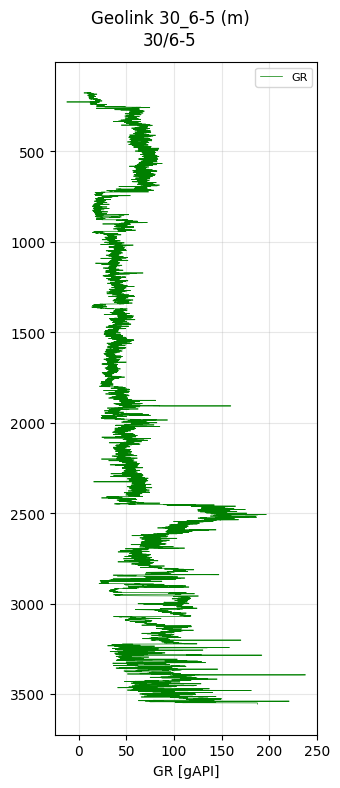

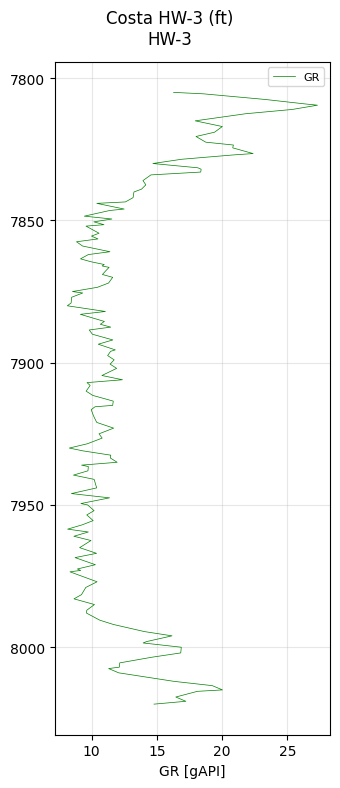

GR ranges -> Geolink: -13..238  |  Costa: 8..27


In [7]:
# GR first-look via the library LogPlot (one single-track plot per well,
# since the two wells are on different depth units - m vs ft).
from petrophys.visualization import LogPlot

for w, title in [(w_geo, 'Geolink 30_6-5 (m)'), (w_car, 'Costa HW-3 (ft)')]:
    lp = LogPlot(w, figsize=(3.5, 8))
    lp.create_figure(n_tracks=1)
    lp.add_curve(0, 'GR', color='green')
    lp.add_title(title)
    lp.show()

print('GR ranges -> Geolink: %.0f..%.0f  |  Costa: %.0f..%.0f'
      % (w_geo.get('GR').min(), w_geo.get('GR').max(),
         w_car.get('GR').min(), w_car.get('GR').max()))

## 6. Curriculum roadmap

The curriculum is split into two parts.

### Part A - Foundations (you are here)
| # | Notebook | What you learn |
|---|---|---|
| 00 | Orientation and setup | This notebook: purpose, data, roadmap |
| 01 | Loading and inspecting data | The `Well` / `Curve` data model in depth |
| 02 | QA/QC and standardization | Conditioning: aliases, units, bad-hole, normalization |

### Part B - Formation evaluation (the physics)
Building on the conditioned data from Part A, Part B works through the classic
interpretation chain:

- **Clay/shale volume** from GR, SP, and neutron-density.
- **Porosity** (density, neutron, sonic, and combined) and effective vs total porosity.
- **Water saturation** (Archie, Simandoux, Indonesia, dual-water, Waxman-Smits) and how
  to choose between them.
- **Permeability** estimation and core calibration.
- **Lithology / multi-mineral solving** (clastic vs carbonate).
- **Reservoir summation**: net pay, bulk-volume water, hydrocarbon pore volume, OOIP/OGIP.
- **Visualization**: triple-combo displays, neutron-density and Pickett crossplots.

Each Part B notebook consumes exactly the `Well` object you learn to build in Part A.

## 7. What is NOT covered yet

To set honest expectations, the current curriculum focuses on **wireline log analysis and
formation evaluation**. The following are outside its present scope:

- **Seismic and AVO** - no seismic inversion, amplitude-versus-offset, or
  rock-physics-to-seismic tie.
- **Geomechanics** - beyond limited digital-core mechanical properties, no full wellbore
  stability / stress modelling.
- **Unconventionals / TOC** - no organic-richness (total organic carbon) or
  source-rock workflows.
- **4D (time-lapse)** - no repeat-survey / production monitoring.
- **Monte-Carlo uncertainty** - results here are deterministic; probabilistic
  uncertainty propagation is not part of this curriculum yet.

Knowing the boundary is part of using any tool responsibly.

## Pitfalls and good habits

- **Mind the depth unit.** Geolink is in metres, Costa in feet. Always read
  `w.depth_unit` before comparing depths or thicknesses across wells.
- **Use `sample()` for paths, never hard-code them.** The bundled data path differs by
  machine; `petrophys.sample(name)` resolves it for you.
- **Non-ASCII header fields happen.** Legacy LAS headers (like the Oseberg field name)
  can carry odd encodings; sanitize before printing if you need clean ASCII output.
- **Core curves are precious.** When a well carries `*_CORE` / `*_CC` curves, use them to
  validate your log-derived answers later in Part B.

## Recap

- *petrophys* is a comprehensive well-log / formation-evaluation platform; every
  sub-package consumes the same `Well` object.
- `petrophys.list_samples(...)` lists bundled wells; `petrophys.sample(name)` gives the
  LAS path to feed `read_las(...)`.
- Two teaching datasets: **Geolink** North Sea clastics (primary well `30_6-5`, metres,
  core-rich) and **Costa** carbonates (`HW-3 ... HW-32`, feet).
- The curriculum runs Part A (foundations / data) then Part B (the interpretation
  physics).
- Seismic/AVO, full geomechanics, unconventionals/TOC, 4D, and Monte-Carlo uncertainty
  are explicitly out of scope for now.

## Try it yourself

> **Exercise 1.** Load a *second* Costa well (e.g. `HW-10`) and a *second* Geolink well
> (e.g. `15_9-14`). Print each well's name, curve count, depth unit and depth range. Do
> all Costa wells share the same curve set? Do they cover the same depth interval?
>
> **Exercise 2.** For any well, list which curves contain the substring `CORE` or `CC`
> (core-calibrated data). Which of the two datasets is richer in core control?

*Hint:* iterate over `petrophys.list_samples('costa')`, and use `read_las(petrophys.sample(name))`.

## What's next

Continue with **`01_loading_and_inspecting_data.ipynb`**, where we open up the `Well` and
`Curve` objects properly: headers, per-curve statistics, DataFrame export, depth slicing,
and the difference between the curve sets of a clastic and a carbonate well.